# 08.03 — Brick 3: Network Construction

This notebook is **only Brick 3**.

It does not label communities.  
It does not discuss central/bridging interpretation deeply.  
It does not model success.

Its job is to answer one reader question:

> How did the plot-similarity relations become a clean analyzable network?

## Thesis-level idea

Brick 2 explained:

```text
plot text → embedding → similarity → neighbor relation
```

Brick 3 explains:

```text
similarity edges → graph → connected component → network quality checks
```

## Figures produced

```text
outputs/thesis_bricks/03_network_construction/figures/
```

1. `01_network_construction_flow.png`  
2. `02_graph_elements_explainer.png`  
3. `03_network_scale_cards.png`  
4. `04_component_retention.png`  
5. `05_degree_distribution.png`  
6. `06_edge_weight_distribution.png`  
7. `07_degree_vs_edge_weight_summary.png`  
8. `08_network_construction_summary.png`  

## Important visual rule

No full 19k-node hairball here.

This brick uses summary views and diagnostics because the reader needs to understand the **construction quality**, not stare at a dense unreadable network.


## 0. Setup

In [ ]:

import os, re, math, textwrap, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import patches
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import matplotlib.patheffects as pe

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 220)

COL = {
    "ink": "#222222",
    "muted": "#62666D",
    "grid": "#E4E7EB",
    "panel": "#F7F8FA",
    "blue": "#2F6FB3",
    "orange": "#D06C45",
    "green": "#2F8F5B",
    "purple": "#7A5BC2",
    "red": "#C94C4C",
    "yellow": "#D9A21B",
    "light_blue": "#E8F1FB",
    "light_orange": "#FBEADF",
    "light_green": "#E6F4EC",
    "light_purple": "#EFEAFB",
    "light_gray": "#F2F4F7",
    "white": "#FFFFFF",
}

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": COL["ink"],
    "axes.labelcolor": COL["ink"],
    "xtick.color": COL["ink"],
    "ytick.color": COL["ink"],
    "text.color": COL["ink"],
    "font.family": "DejaVu Sans",
    "font.size": 12,
    "axes.titlesize": 18,
    "axes.titleweight": "bold",
    "axes.labelsize": 13,
    "xtick.labelsize": 11,
    "ytick.labelsize": 11,
    "legend.fontsize": 11,
    "savefig.dpi": 320,
    "figure.dpi": 130,
})

def save_fig(fig, name, dpi=320):
    png = FIG_DIR / name
    svg = FIG_DIR / name.replace(".png", ".svg")
    fig.savefig(png, dpi=dpi, bbox_inches="tight", facecolor="white")
    fig.savefig(svg, bbox_inches="tight", facecolor="white")
    print("Saved:", png)
    print("Saved:", svg)

def save_table(df, name):
    path = TABLE_DIR / name
    df.to_csv(path, index=False, encoding="utf-8")
    print("Saved:", path)
    return path

def write_text(txt, name):
    path = TEXT_DIR / name
    path.write_text(txt, encoding="utf-8")
    print("Saved:", path)
    return path

def wrap_text(s, width=42):
    if pd.isna(s):
        return ""
    return "\n".join(textwrap.wrap(str(s), width=width))

def shorten(s, width=90):
    if pd.isna(s):
        return ""
    return textwrap.shorten(str(s).replace("\n", " "), width=width, placeholder="...")

def title_block(fig, title, subtitle=None, x=0.05, y=0.965):
    fig.text(x, y, title, ha="left", va="top", fontsize=22, fontweight="bold", color=COL["ink"])
    if subtitle:
        fig.text(x, y - 0.055, subtitle, ha="left", va="top", fontsize=12.5, color=COL["muted"])

def metric_lookup(df, key, default=np.nan):
    if df is None:
        return default
    for col in ["check", "metric"]:
        if col in df.columns:
            s = df[col].astype(str)
            if key in s.values:
                return df.loc[s == key, "value"].iloc[0]
    return default

def detect_edge_cols(df):
    pairs = [("source", "target"), ("source_id", "target_id"), ("src", "dst"), ("u", "v"), ("node1", "node2"), ("from", "to")]
    for a, b in pairs:
        if a in df.columns and b in df.columns:
            return a, b
    return df.columns[0], df.columns[1]

def detect_weight_col(df):
    candidates = []
    for c in df.columns:
        cl = c.lower()
        if any(k in cl for k in ["weight", "similarity", "cosine", "score"]):
            candidates.append(c)
    return candidates[0] if candidates else None

def safe_read(path):
    path = Path(path)
    if path.exists():
        return pd.read_csv(path)
    print("Missing:", path)
    return None

def fmt_int(x):
    try:
        return f"{int(round(float(x))):,}"
    except Exception:
        return "—"

def fmt_float(x, d=3):
    try:
        return f"{float(x):.{d}f}"
    except Exception:
        return "—"


## 1. Project paths

In [ ]:

try:
    from google.colab import drive
    if Path("/content/drive/MyDrive").exists():
        print("Google Drive already mounted.")
    else:
        drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped or failed:", e)

PROJECT_DIR = Path("/content/drive/MyDrive/thesis_movie_project").resolve()

PROCESSED_CORE_DIR = PROJECT_DIR / "processed" / "core"
PROCESSED_NETWORK_DIR = PROJECT_DIR / "processed" / "network"
PROCESSED_FEATURES_DIR = PROJECT_DIR / "processed" / "features"
OUTPUT_TABLES_DIR = PROJECT_DIR / "outputs" / "tables"

FINAL_DIR = PROJECT_DIR / "outputs" / "thesis_bricks" / "03_network_construction"
FIG_DIR = FINAL_DIR / "figures"
TABLE_DIR = FINAL_DIR / "tables"
TEXT_DIR = FINAL_DIR / "text"

for d in [FINAL_DIR, FIG_DIR, TABLE_DIR, TEXT_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print("PROJECT_DIR:", PROJECT_DIR)
print("FINAL_DIR:", FINAL_DIR)


Mounted at /content/drive
PROJECT_DIR: /content/drive/MyDrive/thesis_movie_project
FINAL_DIR: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction


## 2. Load files

In [ ]:

FILES = {
    "semantic": PROCESSED_CORE_DIR / "df_semantic_analysis.csv",
    "nodes": PROCESSED_NETWORK_DIR / "semantic_network_nodes_lcc.csv",
    "edges": PROCESSED_NETWORK_DIR / "semantic_network_edges_mutual_knn.csv",
    "network_audit": PROCESSED_NETWORK_DIR / "network_audit.csv",
    "network_basic": OUTPUT_TABLES_DIR / "network_interpretation_basic_checks.csv",
}

for k, p in FILES.items():
    print(f"{k:18s}", p.exists(), "-", p)

df_semantic = safe_read(FILES["semantic"])
nodes = safe_read(FILES["nodes"])
edges = safe_read(FILES["edges"])
network_audit = safe_read(FILES["network_audit"])
network_basic = safe_read(FILES["network_basic"])

if nodes is None or edges is None:
    raise FileNotFoundError("This brick needs semantic_network_nodes_lcc.csv and semantic_network_edges_mutual_knn.csv.")

source_col, target_col = detect_edge_cols(edges)
weight_col = detect_weight_col(edges)

node_id_col = None
for c in ["tmdb_id", "id", "node_id", "movie_id", "imdb_id"]:
    if c in nodes.columns:
        node_id_col = c
        break
if node_id_col is None:
    node_id_col = nodes.columns[0]

print()
print("nodes:", nodes.shape)
print("edges:", edges.shape)
print("source_col:", source_col)
print("target_col:", target_col)
print("weight_col:", weight_col)
print("node_id_col:", node_id_col)


semantic           True - /content/drive/MyDrive/thesis_movie_project/processed/core/df_semantic_analysis.csv
nodes              True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_nodes_lcc.csv
edges              True - /content/drive/MyDrive/thesis_movie_project/processed/network/semantic_network_edges_mutual_knn.csv
network_audit      False - /content/drive/MyDrive/thesis_movie_project/processed/network/network_audit.csv
network_basic      True - /content/drive/MyDrive/thesis_movie_project/outputs/tables/network_interpretation_basic_checks.csv
Missing: /content/drive/MyDrive/thesis_movie_project/processed/network/network_audit.csv

nodes: (19202, 30)
edges: (86685, 9)
source_col: source_node_id
target_col: target_node_id
weight_col: cosine_similarity
node_id_col: tmdb_id


## 3. Build graph-level diagnostics

In [ ]:

# Construct basic degree and weighted degree from the edge list.
edge_tmp = edges[[source_col, target_col] + ([weight_col] if weight_col else [])].copy()
edge_tmp = edge_tmp.rename(columns={source_col: "source_id", target_col: "target_id"})
if weight_col:
    edge_tmp = edge_tmp.rename(columns={weight_col: "edge_weight"})
else:
    edge_tmp["edge_weight"] = 1.0

# Degree from edges
degree_source = edge_tmp.groupby("source_id").size()
degree_target = edge_tmp.groupby("target_id").size()
degree = degree_source.add(degree_target, fill_value=0).rename("degree_from_edges").reset_index().rename(columns={"index": node_id_col})

# Weighted degree
w_source = edge_tmp.groupby("source_id")["edge_weight"].sum()
w_target = edge_tmp.groupby("target_id")["edge_weight"].sum()
w_degree = w_source.add(w_target, fill_value=0).rename("weighted_degree_from_edges").reset_index().rename(columns={"index": node_id_col})

diagnostic_nodes = nodes.merge(degree, on=node_id_col, how="left").merge(w_degree, on=node_id_col, how="left")
diagnostic_nodes["degree_from_edges"] = diagnostic_nodes["degree_from_edges"].fillna(0)
diagnostic_nodes["weighted_degree_from_edges"] = diagnostic_nodes["weighted_degree_from_edges"].fillna(0)

n_nodes = len(nodes)
n_edges = len(edges)
n_semantic = len(df_semantic) if df_semantic is not None else np.nan
lcc_share = n_nodes / n_semantic * 100 if pd.notna(n_semantic) and n_semantic > 0 else np.nan
avg_degree = 2 * n_edges / n_nodes if n_nodes > 0 else np.nan
density = 2 * n_edges / (n_nodes * (n_nodes - 1)) if n_nodes > 1 else np.nan

n_communities = nodes["community_id"].nunique() if "community_id" in nodes.columns else metric_lookup(network_basic, "n_communities", np.nan)

summary = pd.DataFrame([
    {"metric": "semantic_input_films", "value": n_semantic, "interpretation": "Films available before graph largest-component selection."},
    {"metric": "final_network_nodes", "value": n_nodes, "interpretation": "Films retained in the largest connected component."},
    {"metric": "final_network_edges", "value": n_edges, "interpretation": "Mutual-KNN plot-similarity links in the final graph."},
    {"metric": "largest_component_share_pct", "value": lcc_share, "interpretation": "Share of semantic corpus retained in the analyzable network component."},
    {"metric": "average_degree", "value": avg_degree, "interpretation": "Average number of plot-neighbor links per film."},
    {"metric": "graph_density", "value": density, "interpretation": "Sparse graph density relative to all possible film pairs."},
    {"metric": "detected_communities", "value": n_communities, "interpretation": "Narrative communities detected after graph construction."},
    {"metric": "median_degree", "value": diagnostic_nodes["degree_from_edges"].median(), "interpretation": "Typical number of links per film."},
    {"metric": "median_weighted_degree", "value": diagnostic_nodes["weighted_degree_from_edges"].median(), "interpretation": "Typical summed similarity strength per film."},
])

save_table(summary, "00_network_construction_summary_metrics.csv")
save_table(diagnostic_nodes, "00_network_node_degree_diagnostics.csv")

display(summary)
display(diagnostic_nodes[[node_id_col, "degree_from_edges", "weighted_degree_from_edges"]].head())


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/00_network_construction_summary_metrics.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/00_network_node_degree_diagnostics.csv


,metric,value,interpretation
0,semantic_input_films,20091.000000,Films available before graph largest-component selection.
1,final_network_nodes,19202.000000,Films retained in the largest connected component.
2,final_network_edges,86685.000000,Mutual-KNN plot-similarity links in the final graph.
3,largest_component_share_pct,95.575133,Share of semantic corpus retained in the analyzable network component.
4,average_degree,9.028747,Average number of plot-neighbor links per film.
5,graph_density,0.000470,Sparse graph density relative to all possible film pairs.
6,detected_communities,26.000000,Narrative communities detected after graph construction.
7,median_degree,0.000000,Typical number of links per film.
8,median_weighted_degree,0.000000,Typical summed similarity strength per film.


,tmdb_id,degree_from_edges,weighted_degree_from_edges
0,11232,11.0,5.660847
1,299782,0.0,0.000000
2,23508,0.0,0.000000
3,260443,0.0,0.000000
4,44281,0.0,0.000000


## 4. Figure 1 — Network construction flow

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/01_network_construction_flow.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/01_network_construction_flow.svg


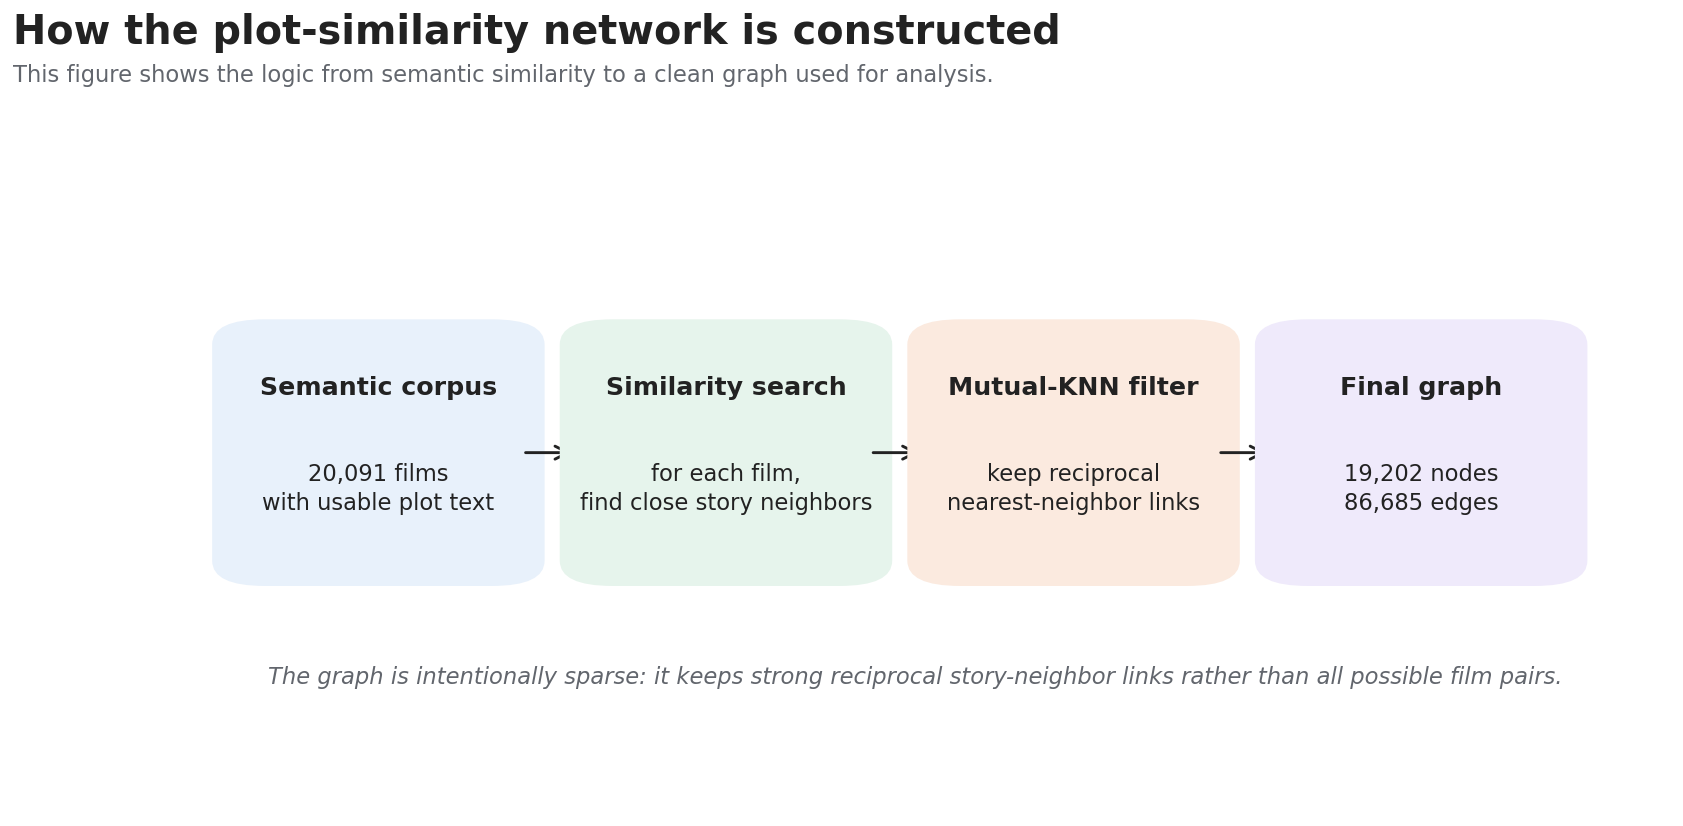

In [ ]:

fig, ax = plt.subplots(figsize=(15, 7.2))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "How the plot-similarity network is constructed",
    "This figure shows the logic from semantic similarity to a clean graph used for analysis."
)

steps = [
    (0.06, "Semantic corpus", f"{fmt_int(n_semantic)} films\nwith usable plot text", COL["light_blue"]),
    (0.29, "Similarity search", "for each film,\nfind close story neighbors", COL["light_green"]),
    (0.52, "Mutual-KNN filter", "keep reciprocal\nnearest-neighbor links", COL["light_orange"]),
    (0.75, "Final graph", f"{fmt_int(n_nodes)} nodes\n{fmt_int(n_edges)} edges", COL["light_purple"]),
]

for i, (x, title, body, color) in enumerate(steps):
    box = FancyBboxPatch(
        (x, 0.34), 0.17, 0.32,
        boxstyle="round,pad=0.025,rounding_size=0.035",
        facecolor=color,
        edgecolor="none"
    )
    ax.add_patch(box)
    ax.text(x + 0.085, 0.58, title, ha="center", fontsize=14, fontweight="bold")
    ax.text(x + 0.085, 0.45, body, ha="center", va="center", fontsize=12.5, linespacing=1.35)

    if i < len(steps) - 1:
        ax.add_patch(FancyArrowPatch(
            (x + 0.18, 0.50),
            (steps[i+1][0] - 0.015, 0.50),
            arrowstyle="->",
            mutation_scale=18,
            lw=1.6,
            color=COL["ink"]
        ))

ax.text(
    0.50, 0.18,
    "The graph is intentionally sparse: it keeps strong reciprocal story-neighbor links rather than all possible film pairs.",
    ha="center",
    fontsize=12.5,
    color=COL["muted"],
    style="italic"
)

save_fig(fig, "01_network_construction_flow.png")
plt.show()


## 5. Figure 2 — Graph elements explainer

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/02_graph_elements_explainer.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/02_graph_elements_explainer.svg


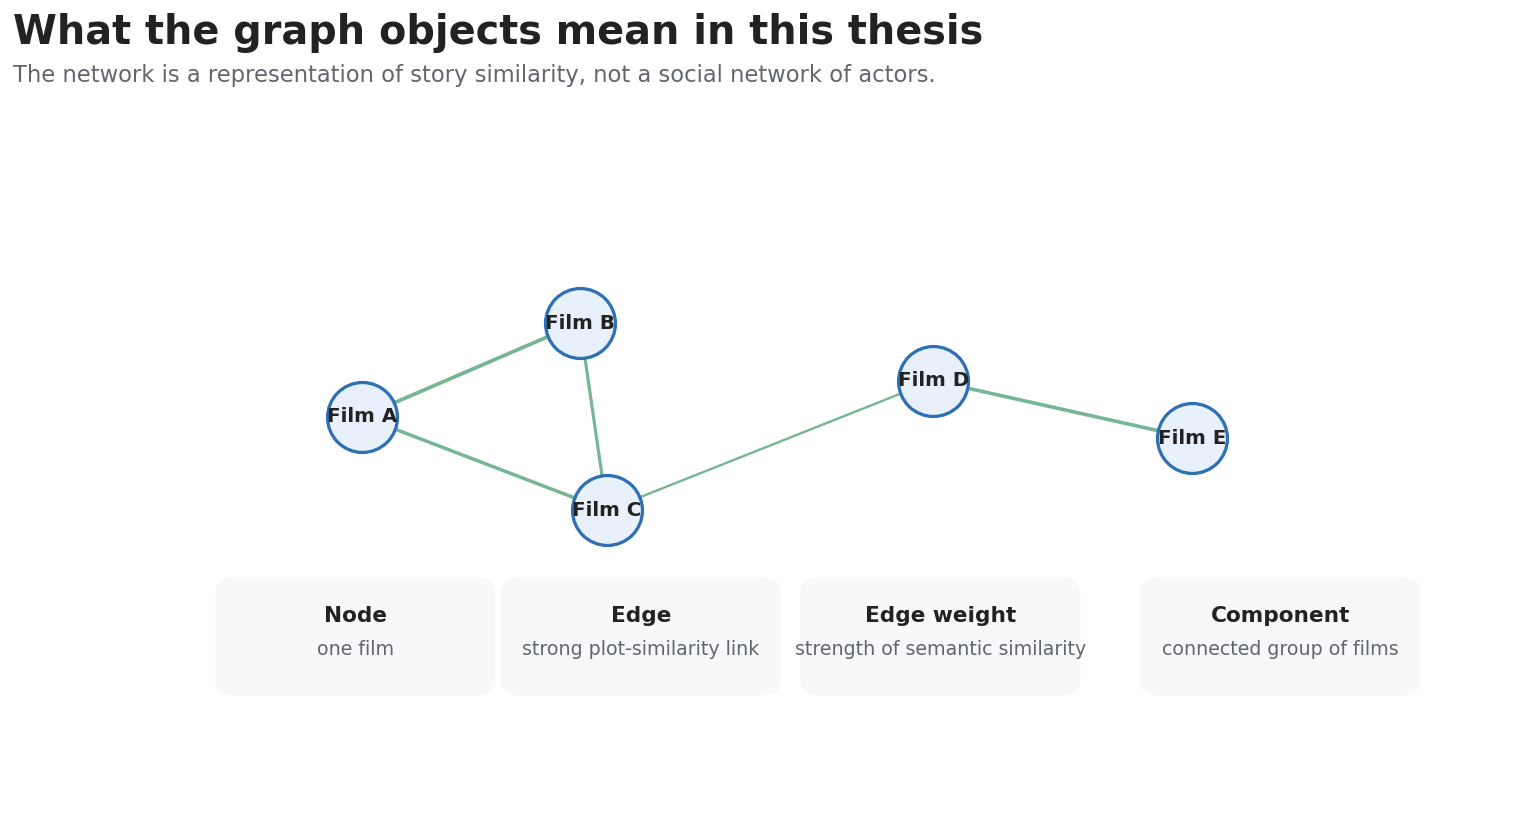

In [ ]:

fig, ax = plt.subplots(figsize=(13.5, 7.2))
ax.axis("off")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

title_block(
    fig,
    "What the graph objects mean in this thesis",
    "The network is a representation of story similarity, not a social network of actors."
)

# Draw toy graph
positions = {
    "Film A": (0.16, 0.55),
    "Film B": (0.32, 0.68),
    "Film C": (0.34, 0.42),
    "Film D": (0.58, 0.60),
    "Film E": (0.77, 0.52),
}

toy_edges = [
    ("Film A", "Film B", 0.92),
    ("Film A", "Film C", 0.88),
    ("Film B", "Film C", 0.84),
    ("Film C", "Film D", 0.73),
    ("Film D", "Film E", 0.90),
]

for a, b, w in toy_edges:
    x1, y1 = positions[a]
    x2, y2 = positions[b]
    ax.plot([x1, x2], [y1, y2], color=COL["green"], lw=1.2 + 4*(w-0.70), alpha=0.65, zorder=1)

for name, (x, y) in positions.items():
    ax.scatter(x, y, s=1500, color=COL["light_blue"], edgecolor=COL["blue"], lw=1.8, zorder=3)
    ax.text(x, y, name, ha="center", va="center", fontsize=11, fontweight="bold", zorder=4)

# Explanation boxes
items = [
    (0.07, 0.18, "Node", "one film"),
    (0.28, 0.18, "Edge", "strong plot-similarity link"),
    (0.50, 0.18, "Edge weight", "strength of semantic similarity"),
    (0.75, 0.18, "Component", "connected group of films"),
]

for x, y, h, body in items:
    ax.add_patch(FancyBboxPatch(
        (x, y), 0.17, 0.13,
        boxstyle="round,pad=0.018,rounding_size=0.02",
        facecolor=COL["panel"],
        edgecolor="none"
    ))
    ax.text(x+0.085, y+0.085, h, ha="center", fontsize=12, fontweight="bold")
    ax.text(x+0.085, y+0.040, body, ha="center", fontsize=10.5, color=COL["muted"])

save_fig(fig, "02_graph_elements_explainer.png")
plt.show()


## 6. Figure 3 — Network scale cards

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/03_network_scale_cards.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/03_network_scale_cards.svg


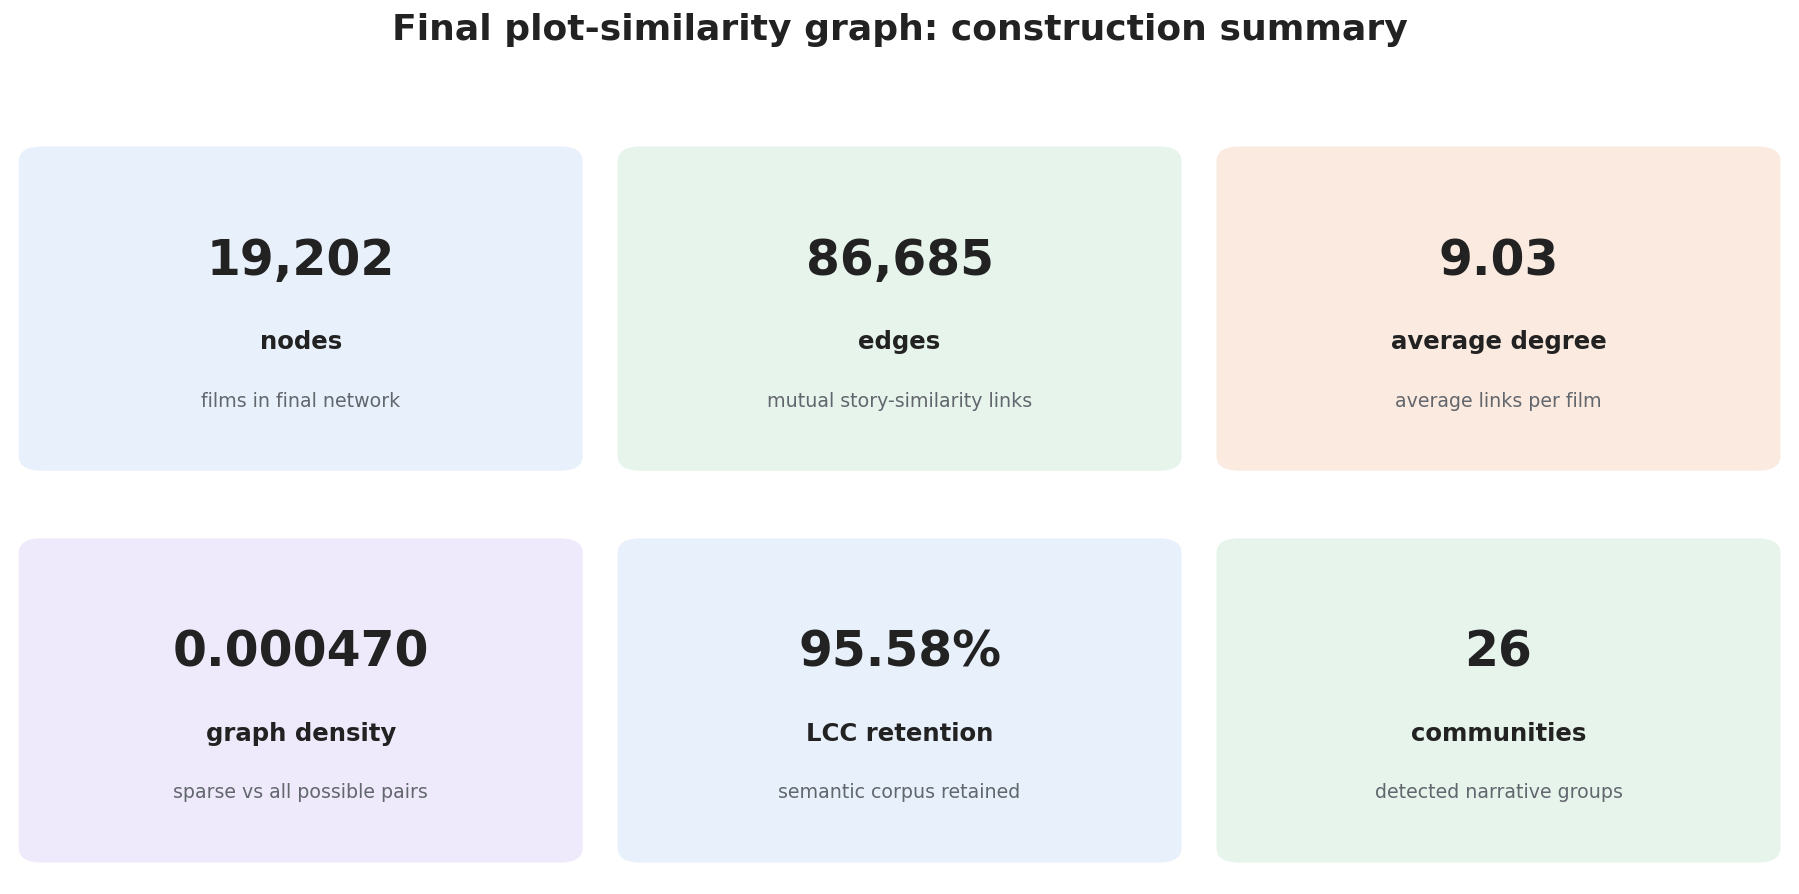

In [ ]:

cards = [
    (fmt_int(n_nodes), "nodes", "films in final network", COL["light_blue"]),
    (fmt_int(n_edges), "edges", "mutual story-similarity links", COL["light_green"]),
    (fmt_float(avg_degree, 2), "average degree", "average links per film", COL["light_orange"]),
    (fmt_float(density, 6), "graph density", "sparse vs all possible pairs", COL["light_purple"]),
    (fmt_float(lcc_share, 2) + "%", "LCC retention", "semantic corpus retained", COL["light_blue"]),
    (fmt_int(n_communities), "communities", "detected narrative groups", COL["light_green"]),
]

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
axes = axes.ravel()

for ax, (value, title, subtitle, bg) in zip(axes, cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=27, fontweight="bold")
    ax.text(0.5, 0.40, title, ha="center", va="center", fontsize=13.5, fontweight="bold")
    ax.text(0.5, 0.24, subtitle, ha="center", va="center", fontsize=10.5, color=COL["muted"])

fig.suptitle("Final plot-similarity graph: construction summary", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])
save_fig(fig, "03_network_scale_cards.png")
plt.show()


## 7. Figure 4 — Component retention

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/04_component_retention_table.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/04_component_retention.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/04_component_retention.svg


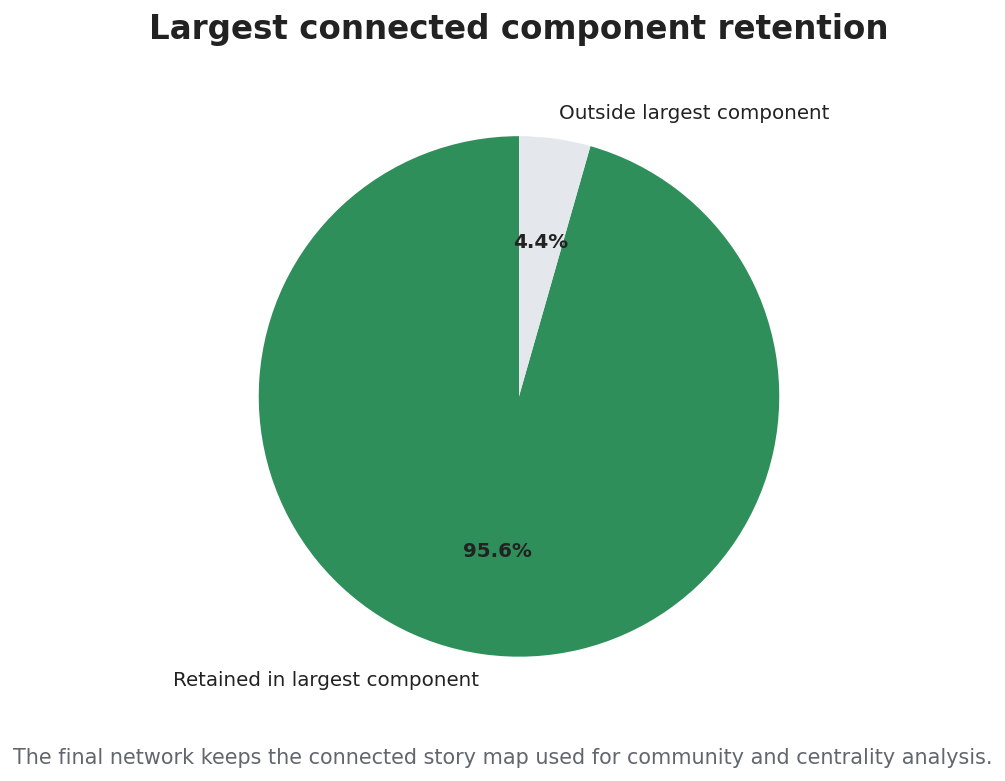

In [ ]:

# Use semantic input and LCC output.
if pd.notna(n_semantic):
    lost = max(n_semantic - n_nodes, 0)
    retention = pd.DataFrame([
        {"stage": "Retained in largest component", "n_films": n_nodes, "share_pct": n_nodes/n_semantic*100},
        {"stage": "Outside largest component", "n_films": lost, "share_pct": lost/n_semantic*100},
    ])
else:
    retention = pd.DataFrame([
        {"stage": "Retained in largest component", "n_films": n_nodes, "share_pct": np.nan},
    ])

save_table(retention, "04_component_retention_table.csv")

fig, ax = plt.subplots(figsize=(10, 6.5))

colors = [COL["green"], COL["grid"]][:len(retention)]
wedges, texts, autotexts = ax.pie(
    retention["n_films"],
    labels=retention["stage"],
    autopct=lambda p: f"{p:.1f}%" if p > 0 else "",
    startangle=90,
    colors=colors,
    textprops={"fontsize": 11}
)

for a in autotexts:
    a.set_fontweight("bold")
    a.set_color(COL["ink"])

ax.set_title("Largest connected component retention", pad=18)
fig.text(
    0.5, 0.06,
    "The final network keeps the connected story map used for community and centrality analysis.",
    ha="center",
    fontsize=11.5,
    color=COL["muted"]
)

save_fig(fig, "04_component_retention.png")
plt.show()


## 8. Figure 5 — Degree distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/05_degree_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/05_degree_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/05_degree_distribution.svg


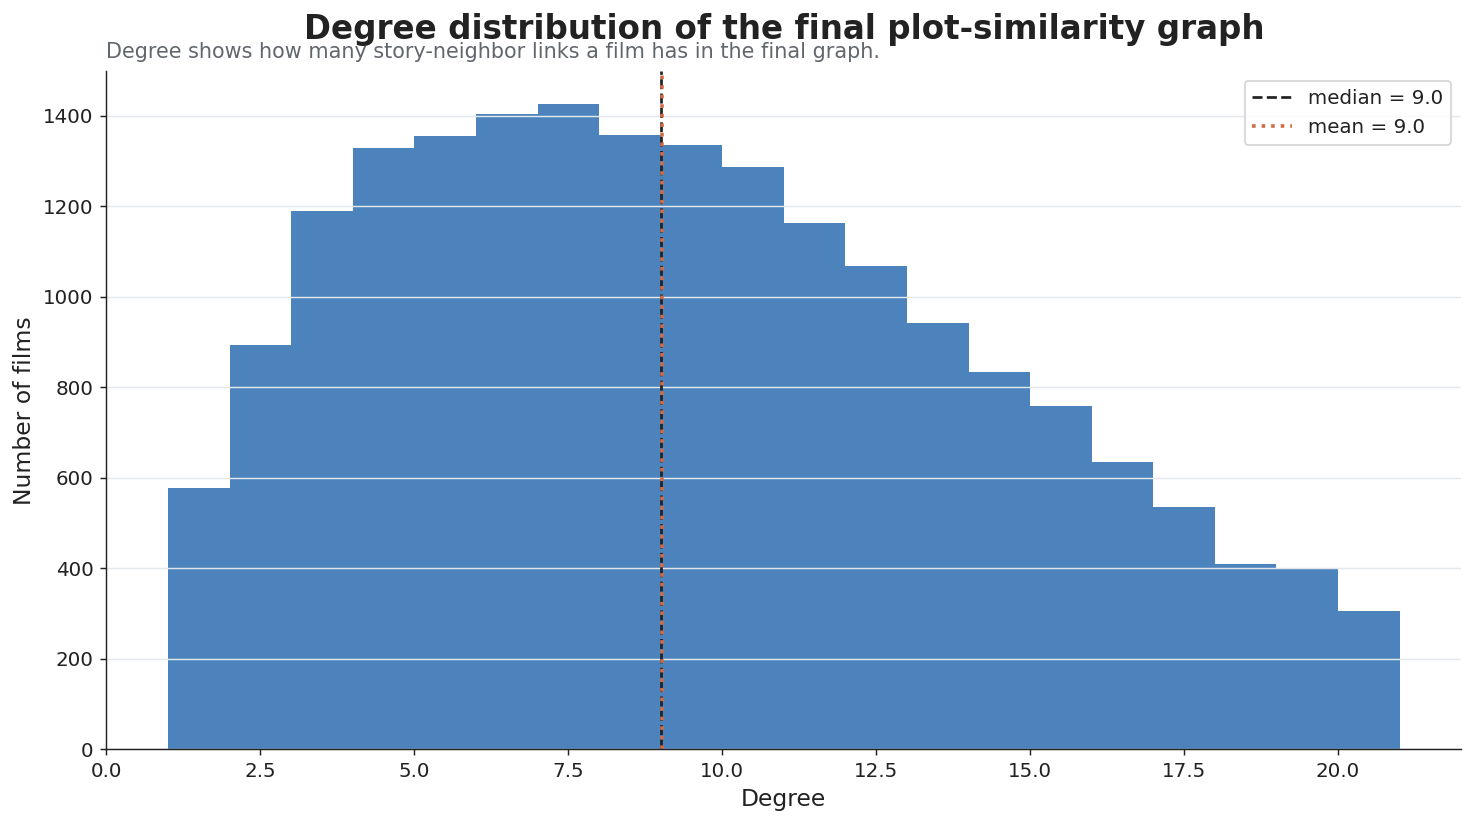

In [ ]:

degree_col = "degree" if "degree" in nodes.columns else "degree_from_edges"
x = diagnostic_nodes[degree_col].dropna() if degree_col in diagnostic_nodes.columns else diagnostic_nodes["degree_from_edges"].dropna()

summary_degree = pd.DataFrame({
    "metric": ["n", "min", "median", "mean", "p75", "p90", "max"],
    "value": [len(x), x.min(), x.median(), x.mean(), x.quantile(0.75), x.quantile(0.90), x.max()]
})
save_table(summary_degree, "05_degree_distribution_summary.csv")

fig, ax = plt.subplots(figsize=(11.5, 6.5))
ax.hist(x, bins=range(int(x.min()), int(x.max()) + 2), color=COL["blue"], alpha=0.86)

ax.axvline(x.median(), color=COL["ink"], ls="--", lw=1.5, label=f"median = {x.median():.1f}")
ax.axvline(x.mean(), color=COL["orange"], ls=":", lw=2.0, label=f"mean = {x.mean():.1f}")

ax.set_title("Degree distribution of the final plot-similarity graph", pad=18)
ax.text(
    0, 1.02,
    "Degree shows how many story-neighbor links a film has in the final graph.",
    transform=ax.transAxes,
    fontsize=11.5,
    color=COL["muted"]
)
ax.set_xlabel("Degree")
ax.set_ylabel("Number of films")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=COL["grid"])
ax.legend()

plt.tight_layout()
save_fig(fig, "05_degree_distribution.png")
plt.show()


## 9. Figure 6 — Edge-weight distribution

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/06_edge_weight_distribution_summary.csv
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/06_edge_weight_distribution.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/06_edge_weight_distribution.svg


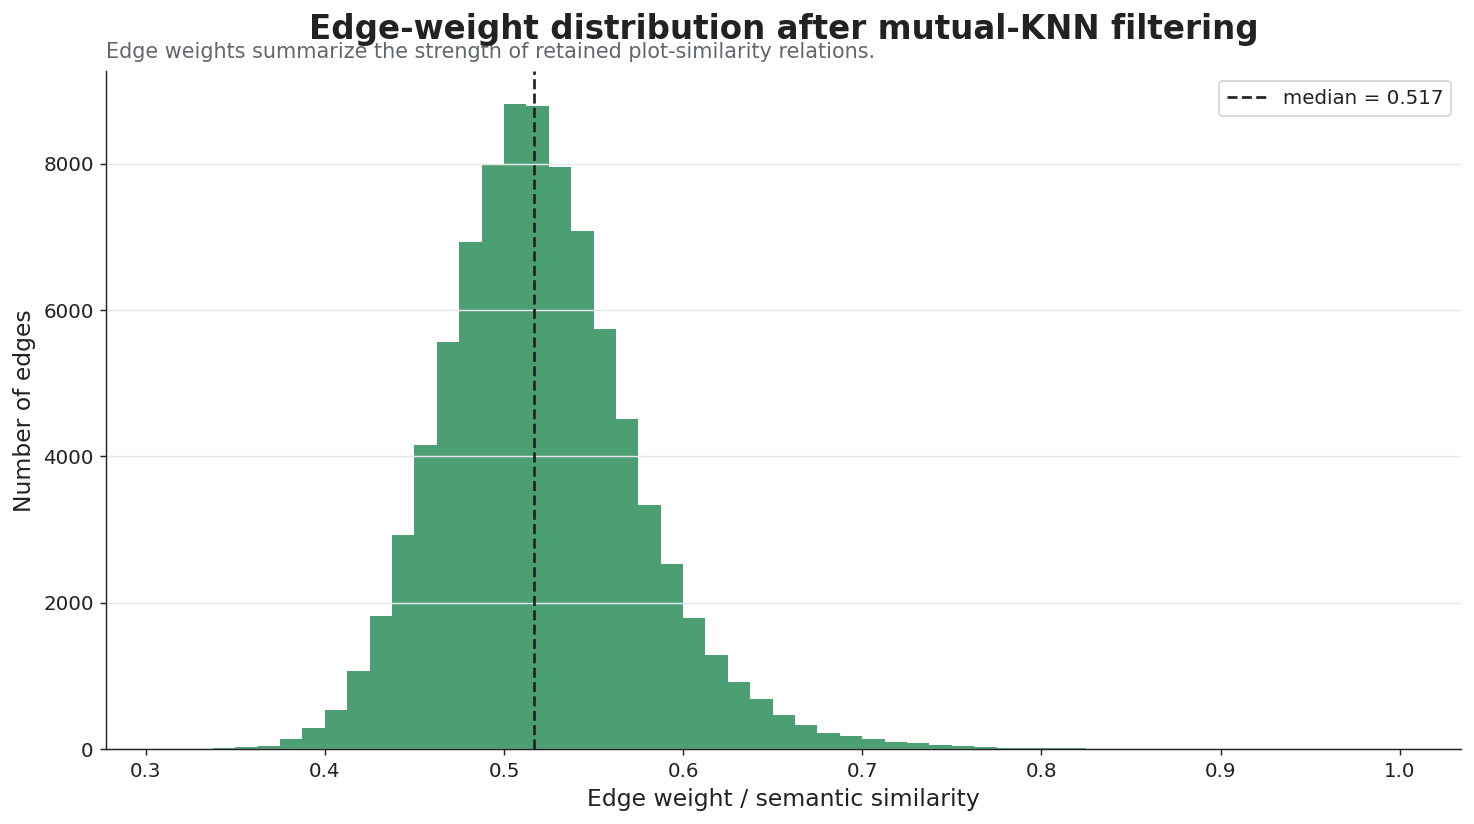

In [ ]:

if "edge_weight" in edge_tmp.columns and edge_tmp["edge_weight"].notna().any():
    x = edge_tmp["edge_weight"].dropna()
    summary_weight = pd.DataFrame({
        "metric": ["n", "min", "median", "mean", "p75", "p90", "max"],
        "value": [len(x), x.min(), x.median(), x.mean(), x.quantile(0.75), x.quantile(0.90), x.max()]
    })
    save_table(summary_weight, "06_edge_weight_distribution_summary.csv")

    fig, ax = plt.subplots(figsize=(11.5, 6.5))
    ax.hist(x, bins=55, color=COL["green"], alpha=0.86)

    ax.axvline(x.median(), color=COL["ink"], ls="--", lw=1.5, label=f"median = {x.median():.3f}")

    ax.set_title("Edge-weight distribution after mutual-KNN filtering", pad=18)
    ax.text(
        0, 1.02,
        "Edge weights summarize the strength of retained plot-similarity relations.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Edge weight / semantic similarity")
    ax.set_ylabel("Number of edges")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "06_edge_weight_distribution.png")
    plt.show()
else:
    print("No usable edge weight column found.")


## 10. Figure 7 — Degree versus weighted degree

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/07_degree_vs_edge_weight_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/07_degree_vs_edge_weight_summary.svg


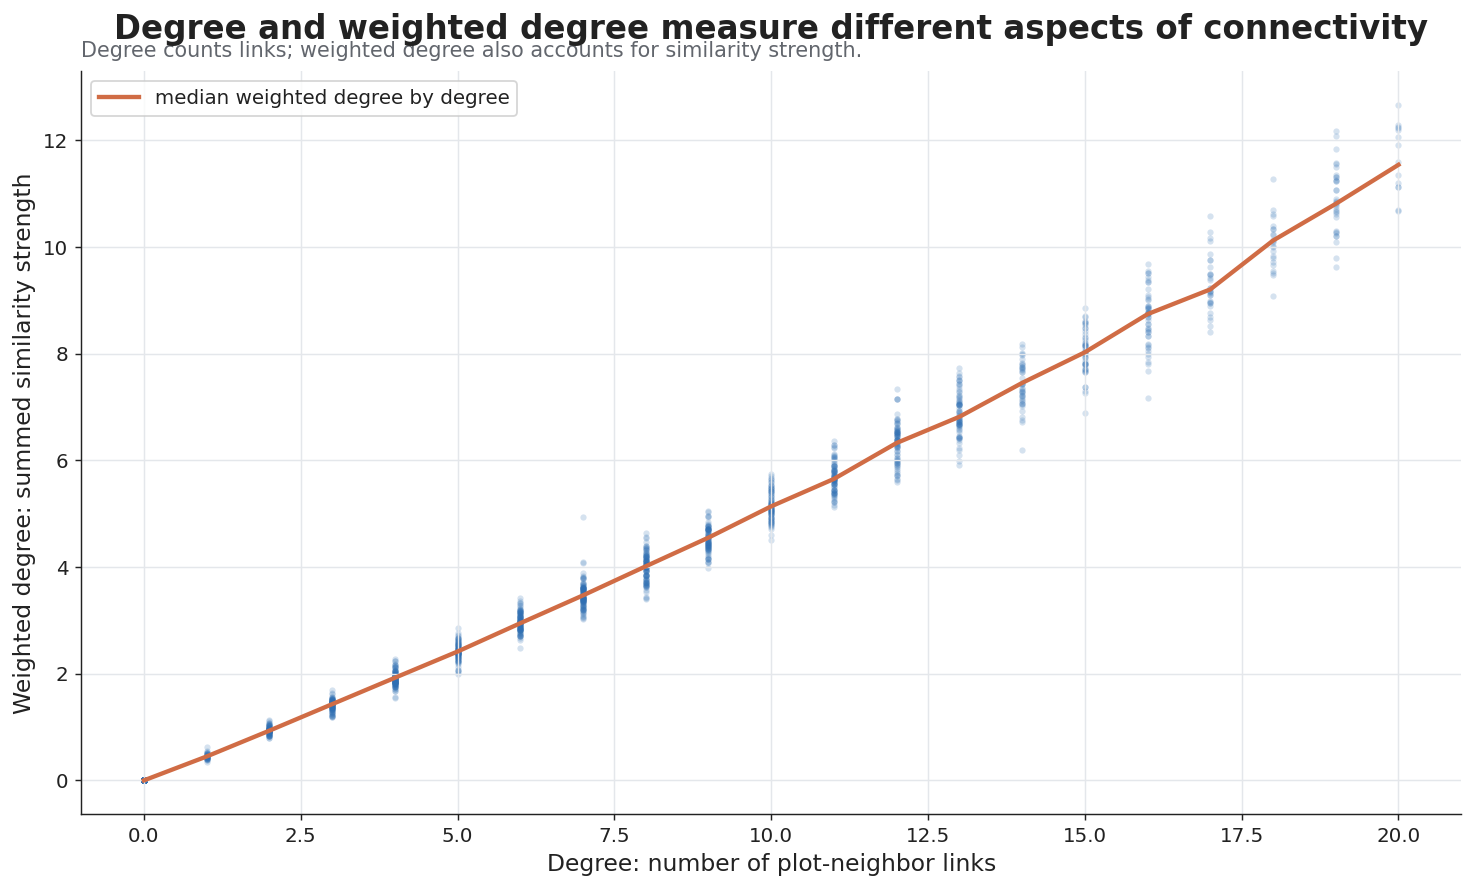

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/tables/07_degree_vs_weighted_degree_trend.csv


In [ ]:

if "degree_from_edges" in diagnostic_nodes.columns and "weighted_degree_from_edges" in diagnostic_nodes.columns:
    plot = diagnostic_nodes.dropna(subset=["degree_from_edges", "weighted_degree_from_edges"]).copy()
    if len(plot) > 7000:
        # Keep random sample for readable scatter.
        plot_bg = plot.sample(7000, random_state=42)
    else:
        plot_bg = plot

    fig, ax = plt.subplots(figsize=(11.5, 7))
    ax.scatter(
        plot_bg["degree_from_edges"],
        plot_bg["weighted_degree_from_edges"],
        s=12,
        alpha=0.20,
        color=COL["blue"],
        linewidth=0
    )

    # Median trend by degree
    trend = (
        plot
        .groupby("degree_from_edges")["weighted_degree_from_edges"]
        .median()
        .reset_index()
        .sort_values("degree_from_edges")
    )
    ax.plot(trend["degree_from_edges"], trend["weighted_degree_from_edges"], color=COL["orange"], lw=2.4, label="median weighted degree by degree")

    ax.set_title("Degree and weighted degree measure different aspects of connectivity", pad=18)
    ax.text(
        0, 1.02,
        "Degree counts links; weighted degree also accounts for similarity strength.",
        transform=ax.transAxes,
        fontsize=11.5,
        color=COL["muted"]
    )
    ax.set_xlabel("Degree: number of plot-neighbor links")
    ax.set_ylabel("Weighted degree: summed similarity strength")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(color=COL["grid"])
    ax.legend()

    plt.tight_layout()
    save_fig(fig, "07_degree_vs_edge_weight_summary.png")
    plt.show()

    save_table(trend, "07_degree_vs_weighted_degree_trend.csv")


## 11. Figure 8 — Network construction summary

Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/08_network_construction_summary.png
Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/figures/08_network_construction_summary.svg


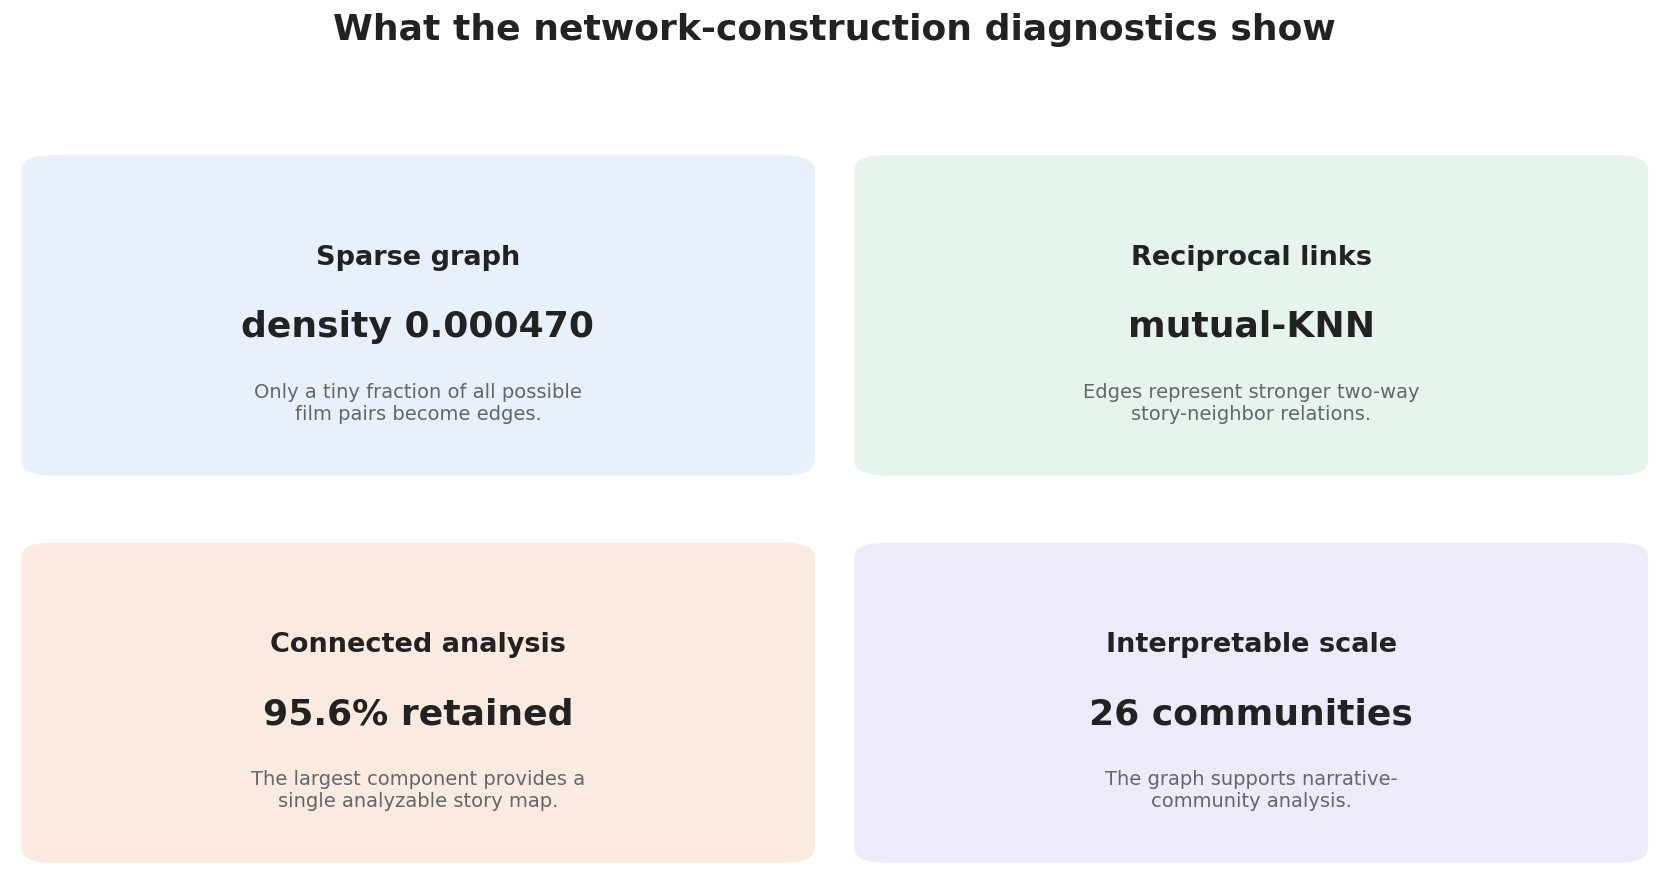

In [ ]:

summary_cards = [
    ("Sparse graph", f"density {fmt_float(density, 6)}", "Only a tiny fraction of all possible film pairs become edges.", COL["light_blue"]),
    ("Reciprocal links", "mutual-KNN", "Edges represent stronger two-way story-neighbor relations.", COL["light_green"]),
    ("Connected analysis", f"{fmt_float(lcc_share, 1)}% retained", "The largest component provides a single analyzable story map.", COL["light_orange"]),
    ("Interpretable scale", f"{fmt_int(n_communities)} communities", "The graph supports narrative-community analysis.", COL["light_purple"]),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
axes = axes.ravel()

for ax, (title, value, desc, bg) in zip(axes, summary_cards):
    ax.axis("off")
    rect = FancyBboxPatch(
        (0.04, 0.08), 0.92, 0.82,
        boxstyle="round,pad=0.03,rounding_size=0.04",
        facecolor=bg,
        edgecolor="none"
    )
    ax.add_patch(rect)
    ax.text(0.5, 0.65, title, ha="center", va="center", fontsize=15, fontweight="bold")
    ax.text(0.5, 0.46, value, ha="center", va="center", fontsize=20, fontweight="bold")
    ax.text(0.5, 0.25, wrap_text(desc, 36), ha="center", va="center", fontsize=10.8, color=COL["muted"])

fig.suptitle("What the network-construction diagnostics show", fontsize=20, fontweight="bold", y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.94])
save_fig(fig, "08_network_construction_summary.png")
plt.show()


## 12. Export interpretation note

In [ ]:

note = f"""
Brick 3 — Network construction interpretation note

This section should appear after the NLP similarity explanation.

Main message:
The thesis turns semantic similarity into a sparse mutual-KNN graph. Each node is a film, and each edge is a retained reciprocal plot-similarity relation. The largest connected component contains {fmt_int(n_nodes)} films and {fmt_int(n_edges)} edges, making it the main network used for community detection and centrality analysis.

Recommended main thesis figures:
1. 01_network_construction_flow.png
2. 02_graph_elements_explainer.png
3. 03_network_scale_cards.png
4. 04_component_retention.png
5. 05_degree_distribution.png

Recommended appendix/supporting figures:
1. 06_edge_weight_distribution.png
2. 07_degree_vs_edge_weight_summary.png
3. 08_network_construction_summary.png

Important wording:
The final network is intentionally sparse. It does not connect every movie to every other movie. It keeps reciprocal local story-neighbor links so that the graph can represent meaningful plot-similarity structure.
""".strip()

write_text(note, "brick_03_interpretation_note.txt")
print(note)


Saved: /content/drive/MyDrive/thesis_movie_project/outputs/thesis_bricks/03_network_construction/text/brick_03_interpretation_note.txt
Brick 3 — Network construction interpretation note

This section should appear after the NLP similarity explanation.

Main message:
The thesis turns semantic similarity into a sparse mutual-KNN graph. Each node is a film, and each edge is a retained reciprocal plot-similarity relation. The largest connected component contains 19,202 films and 86,685 edges, making it the main network used for community detection and centrality analysis.

Recommended main thesis figures:
1. 01_network_construction_flow.png
2. 02_graph_elements_explainer.png
3. 03_network_scale_cards.png
4. 04_component_retention.png
5. 05_degree_distribution.png

Recommended appendix/supporting figures:
1. 06_edge_weight_distribution.png
2. 07_degree_vs_edge_weight_summary.png
3. 08_network_construction_summary.png

Important wording:
The final network is intentionally sparse. It does not

## 13. Output check

In [ ]:

print("Figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print("-", p.name)

print("\nTables:")
for p in sorted(TABLE_DIR.glob("*.csv")):
    print("-", p.name)

print("\nText:")
for p in sorted(TEXT_DIR.glob("*.txt")):
    print("-", p.name)


Figures:
- 01_network_construction_flow.png
- 02_graph_elements_explainer.png
- 03_network_scale_cards.png
- 04_component_retention.png
- 05_degree_distribution.png
- 06_edge_weight_distribution.png
- 07_degree_vs_edge_weight_summary.png
- 08_network_construction_summary.png

Tables:
- 00_network_construction_summary_metrics.csv
- 00_network_node_degree_diagnostics.csv
- 04_component_retention_table.csv
- 05_degree_distribution_summary.csv
- 06_edge_weight_distribution_summary.csv
- 07_degree_vs_weighted_degree_trend.csv

Text:
- brick_03_interpretation_note.txt
